# Whole embryo or 3D pipeline? All pairs, several seeds

`docs/cross_species_alignment_results.md` summarizes the first round of this notebook (X1, X4, X5, seed 0):
- 3D geometry adds little: `PC_fgw` beats `PC_w`, the same solve without the GW term, by only 0.004–0.014 κ_bal.
- Matching each query section on features alone against **all spots of the other embryo** beats `PC_fgw` on all three pairs. It does best with cosine distance and a relaxed target marginal: κ_bal 0.486 at τ_b = 0.7, against 0.409 for `PC_fgw`.
- A Sinkhorn threshold of 1e-5 gives the same scores as 1e-7, in a fraction of the time.
- Settled and dropped from this notebook: semi-relaxed and higher-resolution `PC_w`, choosing τ_b by gene r (it does not work), and the other feature variants (rescaling, whitening, dropping PCs).

That round used three pairs and one seed. This notebook repeats the comparison that survived on **all cross pairs (X1–X6)** and **several seeds** to answer two questions:
1. **All pairs.** Does `cos_w_semi@0.7` beat `PC_fgw` on every pair, including the harder ones? X2 and X3 have the mouse inside the human, and X6 has no depth overlap.
2. **Seeds.** How much do the scores move with the seed, and do the differences between runs keep their sign? The seed changes the Voronoi tiles, the randomized PCAs (the pair embedding and the stack embedding, so the stack too), the 6000-point sample of `PC_*`, the subsample behind the cost scale, and the shuffle behind gene r.

**Before the first run:** the pair features must exist for every pair and seed (`python -m mgw.bench prepare --tier full --pairs X1,X2,X3,X4,X5,X6 --seeds 0,1,2`). The stacks (stage 1) are built and cached on first use, a few minutes per embryo and seed. Results are cached per pair and seed in `<root>/diag/whole_embryo/`, so the notebook can be re-run, or run in parts.

In [1]:
import os
os.environ["OMP_NUM_THREADS"] = os.environ["MKL_NUM_THREADS"] = os.environ["OPENBLAS_NUM_THREADS"] = "8"
os.environ["XLA_PYTHON_CLIENT_ALLOCATOR"] = "platform"   # return JAX's GPU memory after each solve

import sys
sys.path.append("..")

In [2]:
# ============================================================
# Run settings (papermill parameters)
# ============================================================
PAIRS = ("X1", "X2", "X3", "X4", "X5", "X6")  # cross pairs of bench/configs/series.yaml (a = human, b = mouse)
SEEDS = (0, 1, 2)                # the dev seeds of bench.yaml
CONFIG = "bench.yaml"            # benchmark config (bench/configs)
ROOT = None                      # benchmark root; None: $MGW_BENCH_DIR or <data dir>/bench
PIPELINE = "PC_fgw"              # the 3D pipeline whose stacks, point clouds and settings are used
INNER_TOL = 1e-5                 # Sinkhorn threshold; the benchmark's 1e-7 gives the same scores, 7-13 x slower
TAUS_B = (0.95, 0.9, 0.7, 0.5)   # target-side relaxation of the cosine runs (the query side balanced)
REF_TAU_B = 0.7                  # tau_b of the candidate cos_w_semi and of its Euclidean reference E_w_semi
FORCE = False                    # recompute (pair, seed) results that are cached

In [3]:
import dataclasses
import time

import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from ott.geometry import geometry
from ott.problems.linear import linear_problem
from ott.solvers.linear import sinkhorn
from scipy.spatial.distance import cdist

from mgw import crossspecies as cs
from mgw.bench import config, metrics, prepare, series, solvers, volume
from mgw.bench.pipelines import volume as volume_pipeline
from mgw.bench.pipelines.common import Task

assert REF_TAU_B in TAUS_B, "the candidate's tau_b must be one of TAUS_B"
root = prepare.bench_root(ROOT)
cfg = config.load(CONFIG)
ser = series.load(cfg.series_path())
missing = [(pid, s) for pid in PAIRS for s in SEEDS
           if not prepare.feature_file(root, pid, s, cfg.feature_hash()).exists()]
if missing:
    pids, seeds = sorted({p for p, _ in missing}), sorted({s for _, s in missing})
    raise FileNotFoundError(f"no features for {missing}; run first: python -m mgw.bench prepare --tier full "
                            f"--pairs {','.join(pids)} --seeds {','.join(map(str, seeds))}")
OUT = root / "diag" / "whole_embryo"
OUT.mkdir(parents=True, exist_ok=True)
# the cache key: every setting that changes the rows of a (pair, seed)
RUN_KEY = config.short_hash(dict(pipeline=cfg.pipeline_hash(PIPELINE), inner_tol=INNER_TOL, taus_b=TAUS_B,
                                 ref_tau_b=REF_TAU_B))
print(f"root {root}\npairs {PAIRS}, seeds {SEEDS}; results cached in {OUT}")

root /nas/lnt/ga79jin/MGW/data/bench
pairs ('X1', 'X2', 'X3', 'X4', 'X5', 'X6'), seeds (0, 1, 2); results cached in /nas/lnt/ga79jin/MGW/data/bench/diag/whole_embryo


## Helpers

The same helpers as in `section_cost_ablation.ipynb`: the label cost, entropic OT on the cross cost alone (`ot`, with masses and either side relaxed), the soft nearest neighbour (`softmax_nn`, τ_b → 0) and the scores. Each coupling is scored per query section:
- **κ_bal**, as in the benchmark (K: the organs of the whole target embryo);
- **gene r** on the 500 held-out genes: r between each query spot and what the coupling transports to it, minus the same r with the target spots shuffled.

The 3D couplings are mapped back to the real spots exactly as `pipelines/volume.py` does it (`score_volume`).

In [4]:
f_cfg = cfg.raw["features"]


def label_cost(comp_a, comp_b):
    """Organ-label cross cost: 0 same organ, 1 different organs, 0.5 when a side is Other/Excluded."""
    Ka, Kb = metrics.row_normalize(comp_a)[:, metrics.SCORED], metrics.row_normalize(comp_b)[:, metrics.SCORED]
    return 1 - Ka @ Kb.T - 0.5 * (1 - np.outer(Ka.sum(1), Kb.sum(1)))


def ot(M, p, a=None, b=None, tau_a=1.0, tau_b=1.0, epsilon=None):
    """Entropic OT on the cross cost alone: masses a, b (default uniform), unbalanced for tau < 1. (P float32, info)"""
    t0 = time.perf_counter()
    geom = geometry.Geometry(cost_matrix=jnp.asarray(M, dtype=jnp.float32), epsilon=epsilon or p.epsilon)
    a, b = (None if x is None else jnp.asarray(x / np.sum(x), dtype=jnp.float32) for x in (a, b))
    out = sinkhorn.Sinkhorn(max_iterations=p.inner_maxit, threshold=p.inner_tol)(
        linear_problem.LinearProblem(geom, a=a, b=b, tau_a=tau_a, tau_b=tau_b))
    return np.asarray(out.matrix, dtype=np.float32), dict(converged=bool(out.converged),
                                                          seconds=time.perf_counter() - t0)


def softmax_nn(M, eps):
    """tau_b -> 0: each query spot spreads its mass over the target by exp(-M / eps); the target marginal is free."""
    L = -np.asarray(M, dtype=np.float32) / eps
    P = np.exp(L - L.max(1, keepdims=True))
    return P / P.sum(1, keepdims=True) / len(P)


def evaluate(task, d, q, tname, T, Yt, Pq):
    """The scores of a coupling Pq (rows: the spots of query section q) against target compositions T and held-out
    genes Yt (per target column)."""
    r, r0 = cs.coexpression(Pq, q.Y, Yt, seed=task.seed)
    return dict(kappa_bal=task.score(d, q, tname, T, Pq, keep=False)["kappa_bal"],
                gene_r=np.nanmean(r) - np.nanmean(r0))


def cost_scale(Fa, Fb, metric, seed):
    """The benchmark's cost scale (solvers.cost_scale: a quantile of the a x b distances), for any metric."""
    if metric == "euclidean":
        return solvers.cost_scale(Fa, Fb, f_cfg["m_scale_quantile"], f_cfg["m_scale_max_entries"], seed=seed)
    n_cols = max(1, min(len(Fb), f_cfg["m_scale_max_entries"] // max(len(Fa), 1)))
    if n_cols < len(Fb):
        Fb = Fb[np.random.default_rng(seed).choice(len(Fb), n_cols, replace=False)]
    return float(np.quantile(cdist(Fa, Fb, metric), f_cfg["m_scale_quantile"]))

In [5]:
def load(pid, seed):
    """A pair's task (data, cost scale and settings of PIPELINE, Sinkhorn threshold INNER_TOL) and the point clouds
    of both stacks (stage 1)."""
    task = Task(cfg, PIPELINE, ser.pairs[pid], seed, root)
    task.fgw = dataclasses.replace(task.fgw, inner_tol=INNER_TOL)
    sides = {"a": volume_pipeline._side(task, "a_stack"), "b": volume_pipeline._side(task, "b_stack")}
    return dict(task=task, sides=sides, p=task.spec["params"])


def score_volume(ctx, Pdir, run):
    """One row per (direction, query section) of the 3D couplings Pdir ({direction: P}, rows: the query side's
    points), mapped back to the real spots as in pipelines/volume.py."""
    task, p, sides = ctx["task"], ctx["p"], ctx["sides"]
    rows = []
    for d, Pd in Pdir.items():
        (_, STq, mq), (_, STt, mt) = (sides["a"], sides["b"]) if d == "b_stack" else (sides["b"], sides["a"])
        qs, _ = task.sides(d)
        B = volume.target_pool(mt, STt, p["k_target"])
        T, Yt = (np.asarray(B @ STt[k]) for k in ("comp", "Y"))
        for s, name in enumerate(STq["names"]):
            Pq = np.asarray(volume.query_map(mq, STq, s, p["k_query"]) @ Pd)
            rows.append(dict(run=run, kind="3D points", direction=d, query=name, target="points",
                             **evaluate(task, d, qs[name], "points", T, Yt, Pq)))
    return rows


def solve_pc_fgw(ctx):
    """PIPELINE's stage 2, as in pipelines/volume.py: unbalanced FGW of the two point clouds."""
    task, p = ctx["task"], ctx["p"]
    ma, mb = ctx["sides"]["a"][2], ctx["sides"]["b"][2]
    P, _, info = volume.stage2(volume.intra_cost("fgw", ma, cfg), volume.intra_cost("fgw", mb, cfg), ma["F"],
                               mb["F"], task.scale, task.fgw, a=ma["mass"], b=mb["mass"], tau=p["tau"],
                               epsilon=p["epsilon"], unbalanced_correction=p["unbalanced_correction"])
    return P, info


def run_whole(task, specs, metric="euclidean", scale=None):
    """Each query section against all spots of the other embryo: one row per (run, direction, query section).
    specs: [(run, tau_b, cost)], tau_b 1 balanced and 0 the soft nearest neighbour, cost "features" or "labels".
    metric and scale replace the Euclidean distance and its scale."""
    scale = scale or task.scale
    rows = []
    for d in ("b_stack", "a_stack"):
        qs, ts = task.sides(d)
        tname = f"{task.target_embryo(d).name} (all sections)"
        T, Yt = np.vstack([s.comp for s in ts.values()]), np.vstack([s.Y for s in ts.values()])
        Ft = np.vstack([s.emb for s in ts.values()])
        for qn, q in qs.items():
            M = (cdist(q.emb, Ft, metric) / scale).astype(np.float32)
            for run, tb, cost in specs:
                C = label_cost(q.comp, T).astype(np.float32) if cost == "labels" else M
                Pq = softmax_nn(C, task.fgw.epsilon) if tb == 0 else ot(C, task.fgw, tau_b=tb)[0]
                rows.append(dict(run=run, kind="whole embryo", direction=d, query=qn, target=tname,
                                 **evaluate(task, d, q, tname, T, Yt, Pq)))
                del Pq, C
    return rows

## 1. The runs, per pair and seed

All with `INNER_TOL`. **3D, on `PIPELINE`'s point clouds** (stack points, slab masses, `n_samples` points per embryo, the same mapping back to the spots):
- `PC_fgw`: the benchmark pipeline (FGW, α = 0.5, τ = 0.95 on both sides).
- `PC_w`: the same solve without the GW term (masses and τ unchanged). It uses no coordinates.

**Whole embryo, per query section** (all spots of the other embryo, uniform masses, query side balanced, no stack):
- `cos_w_semi@τ_b` for τ_b in `TAUS_B`, and `cos_w_nn` (τ_b → 0): cosine distance between the features. `cos_w_semi@REF_TAU_B` is the candidate.
- `E_w_semi@REF_TAU_B`: the same with Euclidean distance, to check the cosine gain.
- `E_label_nn`: organ labels as the cost, the ceiling. It shows how hard each pair is.

In [6]:
COS_RUNS = ([(f"cos_w_semi@{tb:g}", tb, "features") for tb in TAUS_B]
            + [("cos_w_nn", 0.0, "features"), ("E_label_nn", 0.0, "labels")])
REF, EUC = f"cos_w_semi@{REF_TAU_B:g}", f"E_w_semi@{REF_TAU_B:g}"


def run_one(pid, seed):
    """Every run of one pair and seed: one row per (run, direction, query section)."""
    t0 = time.perf_counter()
    ctx = load(pid, seed)
    task, p = ctx["task"], ctx["p"]
    ma, mb = ctx["sides"]["a"][2], ctx["sides"]["b"][2]
    print(f"  {pid} seed {seed} stage 1: {time.perf_counter() - t0:.0f} s ({len(ma['F'])} x {len(mb['F'])} points)")
    # 3D: the benchmark's FGW and the same solve without the GW term
    t0 = time.perf_counter()
    P, _ = solve_pc_fgw(ctx)
    rows = score_volume(ctx, {"b_stack": P, "a_stack": P.T}, "PC_fgw")
    P, _ = ot(task.cross_cost(ma["F"], mb["F"]), task.fgw, ma["mass"], mb["mass"], p["tau"], p["tau"], p["epsilon"])
    rows += score_volume(ctx, {"b_stack": P, "a_stack": P.T}, "PC_w")
    del P
    print(f"  {pid} seed {seed} 3D runs: {time.perf_counter() - t0:.0f} s")
    # the whole embryo as target: cosine (the tau_b sweep and the label ceiling), then the Euclidean reference
    t0 = time.perf_counter()
    Fa, Fb = (np.vstack([s.emb for s in task.data[side].values()]) for side in ("a", "b"))
    rows += run_whole(task, COS_RUNS, metric="cosine", scale=cost_scale(Fa, Fb, "cosine", seed))
    rows += run_whole(task, [(EUC, REF_TAU_B, "features")])
    print(f"  {pid} seed {seed} whole embryo: {time.perf_counter() - t0:.0f} s")
    return pd.DataFrame(rows).assign(pair=pid, seed=seed)

In [7]:
res = []
for pid in PAIRS:
    for seed in SEEDS:
        f = OUT / f"{pid}_seed{seed}_{RUN_KEY}.csv"
        if f.exists() and not FORCE:
            res.append(pd.read_csv(f))
            print(f"{pid} seed {seed}: cached ({f.name})")
            continue
        t0 = time.perf_counter()
        df = run_one(pid, seed)
        df.to_csv(f, index=False)
        res.append(df)
        print(f"{pid} seed {seed}: {len(df)} rows, {(time.perf_counter() - t0) / 60:.0f} min")
res = pd.concat(res, ignore_index=True)

  CS12-13_E2: 6000 points points, spacing 0.0174


  E9.5_E2: 5998 points points, spacing 0.0336
  X1 seed 0 stage 1: 3 s (6000 x 5998 points)


  X1 seed 0 3D runs: 21 s


  X1 seed 0 whole embryo: 135 s
X1 seed 0: 108 rows, 3 min


INFO     Normalizing spatial coordinates of `x`.                                                                   


...

INFO     Solving problem OTProblem[stage='prepared', shape=(5000, 5000)].                                          


  stack E13.5_E1 (moscot_icp): order ['E13.5_E1S2', 'E13.5_E1S3', 'E13.5_E1S1', 'E13.5_E1S4'] (infer), z [0.0, 0.121, 0.243, 0.337]


  E13.5_E1: 6000 points points, spacing 0.0263
  X6 seed 2 stage 1: 432 s (6000 x 6000 points)


  X6 seed 2 3D runs: 10 s


  X6 seed 2 whole embryo: 75 s
X6 seed 2: 72 rows, 9 min


## 2. Results across pairs

κ_bal and gene r per run and pair. The benchmark scores each seed as the mean over the query sections of both directions; the tables show the mean of that over the seeds. The benchmark also reports the mean of the two direction means; that table follows. Section 3 gives the noise between seeds.

In [8]:
RUN_ORDER = ["PC_fgw", "PC_w", EUC] + [r for r, _, _ in COS_RUNS]
# per (pair, seed, run): the mean over the query sections of both directions
per_seed = res.groupby(["pair", "seed", "run"])[["kappa_bal", "gene_r"]].mean().reset_index()


def per_pair(df, col, order, aggfunc="mean"):
    t = df.pivot_table(index="run", columns="pair", values=col, aggfunc=aggfunc).reindex(order)[list(PAIRS)]
    return t.assign(mean=t.mean(axis=1))


print(f"kappa_bal (mean over the query sections, then over seeds {SEEDS})")
print(per_pair(per_seed, "kappa_bal", RUN_ORDER).round(3).to_string())
print("\ngene r (all held-out genes)")
print(per_pair(per_seed, "gene_r", RUN_ORDER).round(3).to_string())
by_dir = (res.groupby(["pair", "seed", "run", "direction"]).kappa_bal.mean()
          .groupby(["pair", "seed", "run"]).mean().reset_index())
print("\nkappa_bal, mean of the two direction means (the benchmark's convention)")
print(per_pair(by_dir, "kappa_bal", RUN_ORDER).round(3).to_string())
k_mean = per_seed.pivot_table(index="pair", columns="run", values="kappa_bal").loc[list(PAIRS)]
print(f"\n{REF} as a share of the label ceiling: "
      + ", ".join(f"{pid} {v:.2f}" for pid, v in (k_mean[REF] / k_mean.E_label_nn).items()))

kappa_bal (mean over the query sections, then over seeds (0, 1, 2))
pair                X1     X2     X3     X4     X5     X6   mean
run                                                             
PC_fgw           0.354  0.327  0.376  0.441  0.436  0.481  0.402
PC_w             0.350  0.305  0.360  0.431  0.422  0.471  0.390
E_w_semi@0.7     0.387  0.345  0.398  0.476  0.483  0.531  0.437
cos_w_semi@0.95  0.363  0.329  0.409  0.480  0.486  0.518  0.431
cos_w_semi@0.9   0.379  0.343  0.419  0.502  0.509  0.539  0.448
cos_w_semi@0.7   0.409  0.364  0.429  0.524  0.523  0.557  0.468
cos_w_semi@0.5   0.420  0.370  0.431  0.527  0.524  0.561  0.472
cos_w_nn         0.427  0.375  0.431  0.529  0.522  0.563  0.475
E_label_nn       0.973  0.913  0.891  0.892  0.858  0.882  0.902

gene r (all held-out genes)
pair                X1     X2     X3     X4     X5     X6   mean
run                                                             
PC_fgw           0.074  0.086  0.245  0.346  0.500  0.481 

## 3. Seed stability

- **Noise:** the SD over the seeds of each run's κ_bal, per pair. Its median is the noise margin of a single score.
- **Differences:** the three comparisons the conclusions rest on, per pair and seed. Both runs of a difference share the seed's tiles and features, so a difference is less noisy than either score alone. The count gives the (pair, seed) cells in which a difference keeps its sign.
- **τ_b:** the τ_b with the best κ_bal per pair and seed, and how much `REF_TAU_B` gives up against it.

In [9]:
sd = per_pair(per_seed, "kappa_bal", RUN_ORDER, aggfunc="std").drop(columns="mean")
print(f"kappa_bal: SD over seeds {SEEDS}, per run and pair")
print(sd.round(3).to_string())
print(f"\nmedian SD {np.nanmedian(sd.to_numpy()):.3f}, largest {np.nanmax(sd.to_numpy()):.3f}\n")

k = per_seed.pivot_table(index=["pair", "seed"], columns="run", values="kappa_bal")
diffs = {f"{REF} - PC_fgw (the candidate against the benchmark)": k[REF] - k.PC_fgw,
         f"{REF} - {EUC} (cosine against Euclidean)": k[REF] - k[EUC],
         "PC_fgw - PC_w (3D geometry)": k.PC_fgw - k.PC_w}
for name, dv in diffs.items():
    t = dv.unstack("seed").reindex(list(PAIRS))
    t = t.assign(mean=t.mean(axis=1), sd=t.std(axis=1))
    print(f"{name}, kappa_bal\n{t.round(3).to_string()}")
    print(f"> 0 on {(dv > 0).sum()} of {dv.notna().sum()} (pair, seed); mean {dv.mean():+.3f}\n")

TB = {f"cos_w_semi@{tb:g}": tb for tb in TAUS_B} | {"cos_w_nn": 0.0}
best = k[list(TB)].idxmax(axis=1).map(TB).unstack("seed").reindex(list(PAIRS))
print("tau_b with the best kappa_bal (0: cos_w_nn)")
print(best.to_string())
gap = (k[list(TB)].max(axis=1) - k[REF]).unstack("seed").reindex(list(PAIRS))
print(f"\nkappa_bal that {REF} gives up against the best tau_b")
print(gap.round(3).to_string())

kappa_bal: SD over seeds (0, 1, 2), per run and pair
pair                X1     X2     X3     X4     X5     X6
run                                                      
PC_fgw           0.003  0.009  0.013  0.007  0.004  0.003
PC_w             0.004  0.008  0.011  0.005  0.004  0.004
E_w_semi@0.7     0.003  0.002  0.004  0.001  0.001  0.003
cos_w_semi@0.95  0.002  0.002  0.001  0.001  0.002  0.003
cos_w_semi@0.9   0.003  0.003  0.001  0.001  0.002  0.003
cos_w_semi@0.7   0.004  0.003  0.002  0.001  0.002  0.004
cos_w_semi@0.5   0.004  0.002  0.001  0.000  0.002  0.004
cos_w_nn         0.004  0.001  0.002  0.001  0.006  0.005
E_label_nn       0.000  0.000  0.001  0.000  0.001  0.002

median SD 0.002, largest 0.013

cos_w_semi@0.7 - PC_fgw (the candidate against the benchmark), kappa_bal
seed      0      1      2   mean     sd
pair                                   
X1    0.061  0.053  0.052  0.055  0.005
X2    0.031  0.036  0.043  0.037  0.006
X3    0.039  0.059  0.062  0.053  0.012
X4 

### Figure: every run on every pair

Large markers: the mean over the seeds; small dots: each seed (its mean over the query sections). Rows from top: the 3D runs on the point clouds, then the whole-embryo runs. The dashed line marks `PC_fgw`, averaged over the pairs.

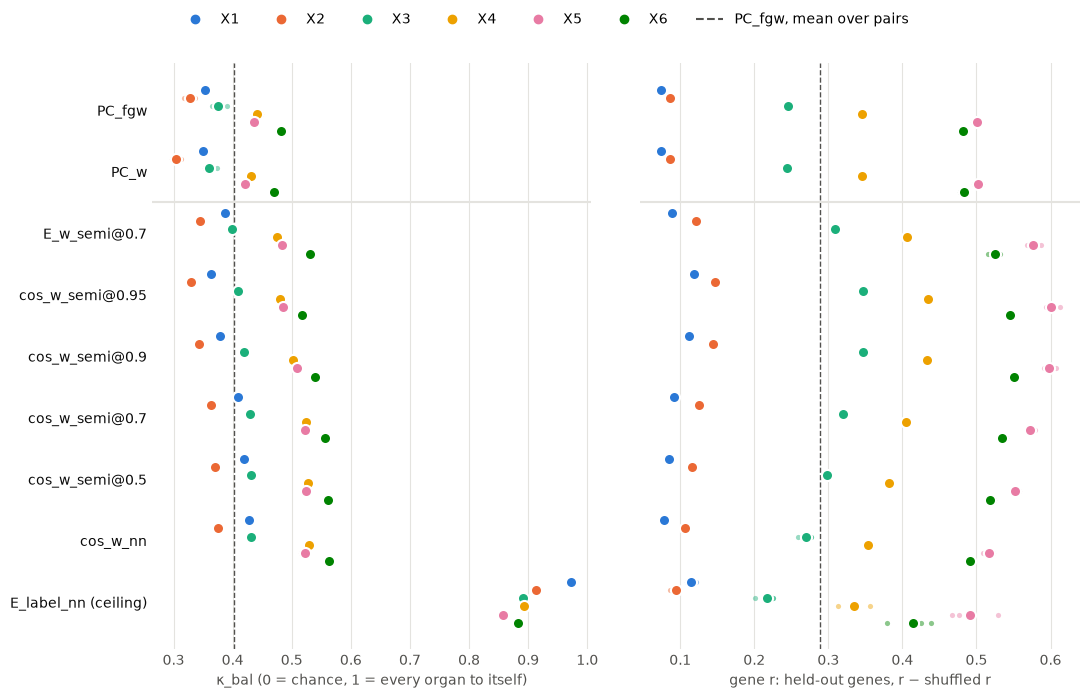

In [10]:
PAIR_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]   # categorical slots, fixed order
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
assert len(PAIRS) <= len(PAIR_COLORS), "more pairs than categorical slots: use small multiples instead"
pair_color = dict(zip(PAIRS, PAIR_COLORS))
step = 0.8 / len(PAIRS)
fig, axes = plt.subplots(1, 2, figsize=(11, 0.6 * len(RUN_ORDER) + 1.6), sharey=True)
for ax, col, xlabel in ((axes[0], "kappa_bal", "κ_bal (0 = chance, 1 = every organ to itself)"),
                        (axes[1], "gene_r", "gene r: held-out genes, r − shuffled r")):
    for j, pid in enumerate(PAIRS):
        off = (j - (len(PAIRS) - 1) / 2) * step
        for i, run in enumerate(RUN_ORDER):
            v = per_seed[(per_seed.run == run) & (per_seed.pair == pid)][col].to_numpy()
            if len(v):
                ax.scatter(v, np.full(len(v), i + off), s=14, color=pair_color[pid], alpha=0.45, linewidths=0)
                ax.scatter([np.nanmean(v)], [i + off], s=64, color=pair_color[pid], edgecolors="white",
                           linewidths=1.5, zorder=3)
    ax.axvline(per_seed[per_seed.run == "PC_fgw"].groupby("pair")[col].mean().mean(), color=MUTED, ls="--", lw=1)
    ax.axhline(RUN_ORDER.index(EUC) - 0.5, color=GRID, lw=1.5)
    ax.set_xlabel(xlabel, color=MUTED)
    ax.tick_params(colors=MUTED, length=0)
    ax.grid(axis="x", color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    for s in ax.spines.values():
        s.set_visible(False)
axes[0].set_yticks(range(len(RUN_ORDER)), [f"{r} (ceiling)" if "label" in r else r for r in RUN_ORDER], color=INK)
axes[0].invert_yaxis()
fig.legend(handles=[Line2D([], [], marker="o", ls="", color=pair_color[p], label=p) for p in PAIRS]
           + [Line2D([], [], ls="--", color=MUTED, label="PC_fgw, mean over pairs")],
           loc="upper center", ncol=len(PAIRS) + 1, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 1 - 0.45 / fig.get_figheight()), w_pad=3)
plt.show()

## How to read the results

- **`cos_w_semi@REF_TAU_B − PC_fgw` > 0 in every (pair, seed) cell, and well above the median SD:** the whole-embryo baseline holds beyond X1, X4 and X5 and can replace `PC_fgw` as the reference (next step: make it a benchmark pipeline). If it loses on X2, X3 or X6, look at the label ceiling of that pair first: the pair may be hard for every run.
- **`PC_fgw − PC_w` within the noise on most pairs:** 3D geometry adds nothing to the cross-species step, now on all pairs. A pair where it is clearly positive is where to look for a use of stage 1.
- **Cosine against Euclidean:** a gain on every pair and seed confirms cosine as the default distance.
- **Seeds:** the median SD replaces the "0.01–0.02" guess as the margin below which two runs cannot be told apart. If one pair's SD is much larger, its stack or its features depend on the seed more than the others'.
- **τ_b:** if the best τ_b is ≤ 0.7 for every pair and seed and the gap of `REF_TAU_B` is small, τ_b = 0.7 can be fixed for the benchmark. If the best τ_b differs between pairs, τ_b needs a label-free criterion (gene r is not one, see the doc).